# 01. Data audit (Consistency)

**Goal.** Look at the Consistency dataset before any model does: what is in it, what is wrong with it, and what that means for the
experiments. Nothing here is fitted or tuned.

**Task.** Predict the Consistency score (0-1) of one student in one sprint from the four proposal features `AWR` (share of the 14 days with a commit), `1 - DC` (work not crowded at the deadline), `1 - LI` (no long idle stretch) and `1 - CV` (even rhythm). The label is the rater's `(R_avg - 1) / 4` over the four Consistency criteria.

The same five student-disjoint groups and the same 20 rated records are used as for Effort.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="consistency", title="Consistency", folder=Path(".").resolve(), dataset_file="consistency_dataset.csv", label="rater_consistency", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')]
VARIANTS = {'proposal 4': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus')], 'proposal 4 + no-activity flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_no_activity', 'raw')], 'proposal 4 + bimodal flag': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_bimodal', 'raw')], 'proposal 4 + first active day': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus'), ('C_CV_norm', 'one_minus'), ('C_first_active_day', 'raw')], '3 features (no CV)': [('C_AWR', 'raw'), ('C_DC', 'one_minus'), ('C_LI_norm', 'one_minus')], 'AWR + 1-DC': [('C_AWR', 'raw'), ('C_DC', 'one_minus')], 'AWR only': [('C_AWR', 'raw')], 'commits (log) + AWR': [('E_CC', 'log'), ('C_AWR', 'raw')]}
FEATURES = ['C_AWR', 'C_DC', 'C_LI_norm', 'C_CV_norm']
ZERO_RULE_OK = True
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

Consistency (744, 25)


## 1. Size and structure

In [2]:
sizes = pd.DataFrame({
    "real records": real.groupby("group").size(), "rated (ground truth)": gold.groupby("group").size(),
    "no commits": real[real[ACT] == 0].groupby("group").size(), "students": real.groupby("group").student_id.nunique(),
    "teams": real.groupby("group").team_id.nunique(), "synthetic": syn.groupby("group").size(),
}).fillna(0).astype(int)
sizes.loc["total"] = sizes.sum()
assert (real.groupby("student_id").group.nunique() == 1).all(), "a student appears in more than one group"
print("every student belongs to exactly one group")
sizes

every student belongs to exactly one group


,real records,rated (ground truth),no commits,students,teams,synthetic
group,,,,,,
A,71,7,22,8,6,294
B,28,4,5,5,3,146
C,21,4,5,5,2,66
D,16,3,1,4,2,69
E,8,2,4,4,1,25
total,144,20,37,26,14,600


## 2. Missing, impossible and duplicate values

In [3]:
def share_missing(frame):
    return frame[FEATURES].isna().mean()

miss = pd.DataFrame({"real: share missing": share_missing(real), "synthetic: share missing": share_missing(syn),
                     "rated: missing": gold[FEATURES].isna().sum()})
print("duplicate record ids:", int(d.record_id.duplicated().sum()), "| labels outside 0-1:", int(((d.label < 0) | (d.label > 1)).sum()))
if True:
    print("feature values outside 0-1:", int(((d[FEATURES] < 0) | (d[FEATURES] > 1)).sum().sum()))
miss.round(3)

duplicate record ids: 0 | labels outside 0-1: 0
feature values outside 0-1: 0


,real: share missing,synthetic: share missing,rated: missing
C_AWR,0.0,0.0,0
C_DC,0.0,0.0,0
C_LI_norm,0.0,0.0,0
C_CV_norm,0.0,0.0,0


## 3. Feature distributions

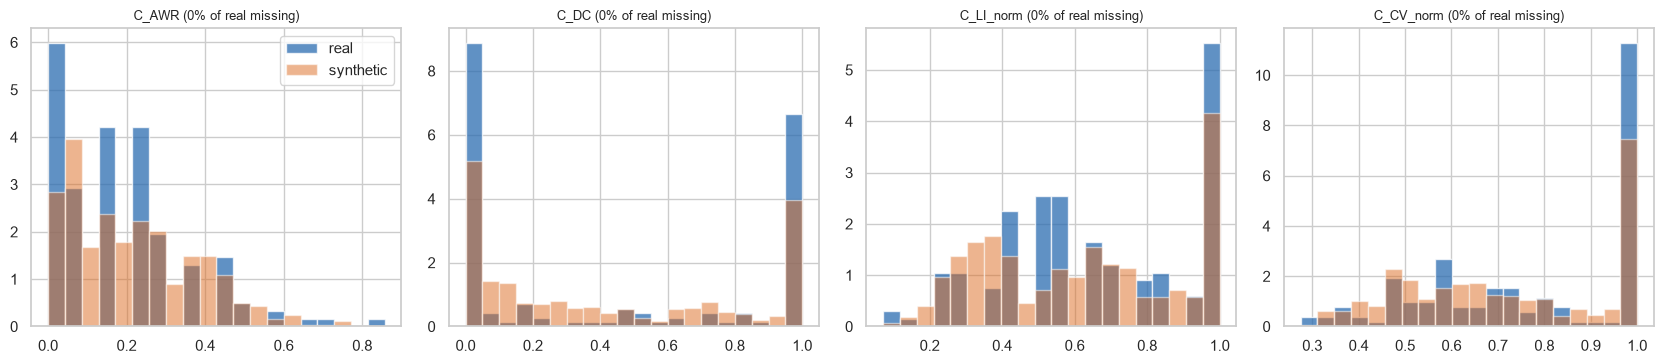

,distinct values,zero share,median,max,skew
feature,,,,,
C_AWR,12,0.26,0.14,0.86,1.17
C_DC,40,0.41,0.17,1.00,0.28
C_LI_norm,14,0.00,0.64,1.00,-0.08
C_CV_norm,87,0.00,0.78,1.00,-0.35


In [4]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(4.2 * len(FEATURES), 3.8))
for a, f in zip(np.atleast_1d(axes), FEATURES):
    x, y = real[f].dropna(), syn[f].dropna()
    bins = np.linspace(min(x.min(), y.min()), max(x.max(), y.max()), 21)
    a.hist(x, bins=bins, color="#2b6cb0", alpha=.75, density=True, label="real")
    a.hist(y, bins=bins, color="#dd6b20", alpha=.5, density=True, label="synthetic")
    a.set_title(f"{f} ({100 * real[f].isna().mean():.0f}% of real missing)", fontsize=9)
np.atleast_1d(axes)[0].legend()
fig.tight_layout()
plt.show()
rows = []
for f in FEATURES:
    x = real[f].dropna()
    rows.append({"feature": f, "distinct values": x.nunique(), "zero share": (x == 0).mean(), "median": x.median(), "max": x.max(), "skew": x.skew()})
pd.DataFrame(rows).set_index("feature").round(2)

## 4. Overlap between features

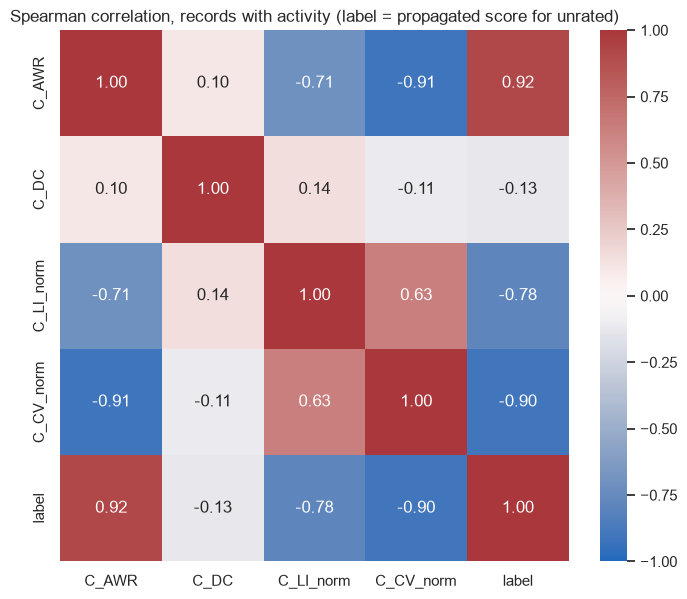

In [5]:
corr = active[FEATURES + ["label"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(1.3 * len(FEATURES) + 3, 1.1 * len(FEATURES) + 2.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation, records with activity (label = propagated score for unrated)")
plt.show()

## 5. The labelled records

count    20.000
mean      0.228
std       0.224
min       0.000
25%       0.047
50%       0.156
75%       0.328
max       0.688
distinct label values: [np.float64(0.0), np.float64(0.062), np.float64(0.125), np.float64(0.188), np.float64(0.25), np.float64(0.312), np.float64(0.375), np.float64(0.5), np.float64(0.688)]


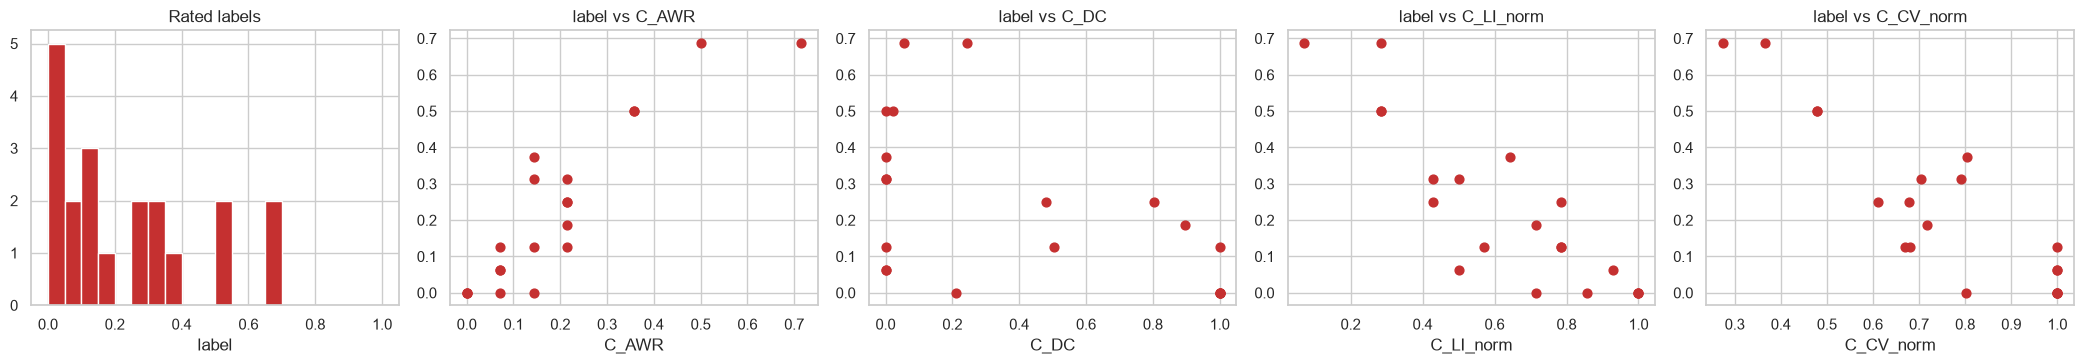

,Spearman with the rated label,rated records with the feature
C_AWR,0.87,20
C_DC,-0.47,20
C_LI_norm,-0.85,20
C_CV_norm,-0.82,20


In [6]:
print(gold[LABEL].describe().round(3).to_string())
print("distinct label values:", sorted(gold[LABEL].round(3).unique()))
fig, axes = plt.subplots(1, len(FEATURES) + 1, figsize=(4.2 * (len(FEATURES) + 1), 3.8))
axes[0].hist(gold[LABEL], bins=np.linspace(0, 1, 21), color="#c53030")
axes[0].set(title="Rated labels", xlabel="label")
for a, f in zip(axes[1:], FEATURES):
    a.scatter(gold[f], gold[LABEL], s=40, color="#c53030")
    a.set(title=f"label vs {f}", xlabel=f)
fig.tight_layout()
plt.show()
rel = pd.DataFrame({"Spearman with the rated label": [gold[[f, LABEL]].dropna().corr(method="spearman").iloc[0, 1] for f in FEATURES],
                    "rated records with the feature": [int(gold[f].notna().sum()) for f in FEATURES]}, index=FEATURES)
rel.round(2)

## 6. Records with no activity

In [7]:
inactive = real[real[ACT] == 0]
print(f"{len(inactive)} of {len(real)} real records ({len(inactive) / len(real):.0%}) have no commits")
print("rated inactive records:", len(gold[gold[ACT] == 0]), "| their labels:", sorted(gold[gold[ACT] == 0][LABEL].round(2).tolist()))
print("what the features show for inactive records:")
inactive[FEATURES].describe().loc[["mean", "min", "max"]].round(2)

37 of 144 real records (26%) have no commits
rated inactive records: 3 | their labels: [0.0, 0.0, 0.0]
what the features show for inactive records:


,C_AWR,C_DC,C_LI_norm,C_CV_norm
mean,0.0,1.0,1.0,1.0
min,0.0,1.0,1.0,1.0
max,0.0,1.0,1.0,1.0


## 7. Team size and synthetic records

In [8]:
print("median of the first feature by team size (active records):")
print(active.groupby("team_size")[FEATURES[0]].median().round(2).to_dict())
print("zero-activity share: real", round((real[ACT] == 0).mean(), 2), "| synthetic", round((syn[ACT] == 0).mean(), 2))
print("synthetic rows whose parents are in different groups:", int((syn.parents_in_group == 0).sum()), "of", len(syn))

median of the first feature by team size (active records):
{3.0: 0.21, 4.0: 0.21, 5.0: 0.36}
zero-activity share: real 0.26 | synthetic 0.12
synthetic rows whose parents are in different groups: 392 of 600


## 8. What this means

| Finding | Consequence |
|---|---|
| No missing values; all four features are inside 0-1 | No cleaning needed |
| 37 of 144 real records (26%) have no commits; their features are fixed at the worst values (`AWR` 0, `DC` 1, `LI` 1, `CV` 1), and all three rated inactive records are labelled 0 | Consistency is *undefined* for them, not "worst". Notebook 03 tests treating them by a rule (predict 0, train on active students only) against treating them as ordinary rows |
| `AWR` takes only 12 distinct values (days active out of 14); `DC` is 0 for 41% (nothing in the last 3 days) | Coarse, discrete features; trees will split on a handful of values |
| Against the rated label: `AWR` 0.87, `LI` -0.85, `CV` -0.82, `DC` -0.47 (Spearman) | Three features carry most of the signal and are strongly related to each other; `DC` is the weakest |
| Rated labels span 0-0.69 (mean 0.23) | Most students are inconsistent; very steady students are absent from the labels |
| Median `AWR` is 0.36 in 5-person teams vs 0.21 in 3-4 person teams | Team size shifts the feature; whether to adjust is not tested here |
| 392 of 600 synthetic rows have parents in different groups | Excluded from training by the rule in notebook 02 |

Next: **02. Splits and baselines**.